In [30]:
# Import standard Python libraries for file handling, plotting, math, and data tables
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Set up folder paths where the simulation data and output charts are stored
PROJECT_DIR = Path(
    r"C:\Users\Karthi\Qauntum"
)

RESULTS_DIR = PROJECT_DIR / "results"
FIGURE_DIR = PROJECT_DIR / "figures"

# Load the summary results from a Quantum Error Correction (QEC) simulation
# Context: Quantum bits (qubits) are very noisy and prone to errors.
# A surface code groups many physical qubits together to protect a single reliable logical qubit
# Noise levels = physical_error_probability
summary_path = (
    RESULTS_DIR
    / "surface_code_threshold_summary.csv"
)
# Display the raw simulation table
threshold_df = pd.read_csv(
    summary_path
)

threshold_df

,code,distance,rounds,physical_error_probability,decoder,shots,discards,retained_shots,logical_errors,logical_error_rate,standard_error,confidence_lower_95,confidence_upper_95,zero_error_upper_bound_95,cpu_seconds,shots_per_cpu_second,strong_id,metadata_json
0,surface_code:rotated_memory_x,3,3,0.003,pymatching,144657,0,144657,1000,0.006913,0.000218,0.006486,0.007340,NaN,0.040558,3.566679e+06,b27ff17fb39aa190108bb3aca7d2bf9a2760d4f3363e00...,"{""code"": ""surface_code:rotated_memory_x"", ""dis..."
1,surface_code:rotated_memory_x,3,3,0.004,pymatching,79121,0,79121,1001,0.012652,0.000397,0.011873,0.013430,NaN,0.030896,2.560840e+06,af415813141989a7c55f2def163e1ee973707ac0f4cfb9...,"{""code"": ""surface_code:rotated_memory_x"", ""dis..."
2,surface_code:rotated_memory_x,3,3,0.005,pymatching,52497,0,52497,1001,0.019068,0.000597,0.017898,0.020238,NaN,0.023881,2.198293e+06,db4bbf34845882578b9da4954d199c207e9aa60da920fc...,"{""code"": ""surface_code:rotated_memory_x"", ""dis..."
3,surface_code:rotated_memory_x,3,3,0.006,pymatching,39185,0,39185,1026,0.026183,0.000807,0.024602,0.027765,NaN,0.021757,1.801054e+06,fcb5dd1d202ef3d42e78fb3760127fa72f13c8ee74ee80...,"{""code"": ""surface_code:rotated_memory_x"", ""dis..."
4,surface_code:rotated_memory_x,3,3,0.007,pymatching,28945,0,28945,1031,0.035619,0.001089,0.033484,0.037754,NaN,0.019516,1.483104e+06,f811c50cfc13b443fb3fdb7fee0477543b1e5b24e92a9a...,"{""code"": ""surface_code:rotated_memory_x"", ""dis..."
5,surface_code:rotated_memory_x,3,3,0.008,pymatching,21777,0,21777,1013,0.046517,0.001427,0.043720,0.049314,NaN,0.011542,1.886827e+06,dbf4b165c812c8a3c23f0388617f288a230a11cb407fe5...,"{""code"": ""surface_code:rotated_memory_x"", ""dis..."
6,surface_code:rotated_memory_x,3,3,0.009,pymatching,18705,0,18705,1031,0.055119,0.001669,0.051848,0.058389,NaN,0.016645,1.123774e+06,42447ccc9c82310f9488ad0be1db266c935ffb7094ba47...,"{""code"": ""surface_code:rotated_memory_x"", ""dis..."
7,surface_code:rotated_memory_x,3,3,0.010,pymatching,15633,0,15633,1047,0.066974,0.001999,0.063055,0.070892,NaN,0.019306,8.097399e+05,72bc659b44be4b0e4daf7397a5c77cb4a88cd27c261ad5...,"{""code"": ""surface_code:rotated_memory_x"", ""dis..."
8,surface_code:rotated_memory_x,3,3,0.012,pymatching,11537,0,11537,1081,0.093699,0.002713,0.088381,0.099016,NaN,0.014027,8.225087e+05,280764b4ede783325e0bfed77d6ad7ef9fe6d6d3492fe2...,"{""code"": ""surface_code:rotated_memory_x"", ""dis..."
9,surface_code:rotated_memory_x,3,3,0.015,pymatching,8465,0,8465,1035,0.122268,0.003561,0.115289,0.129247,NaN,0.011751,7.203765e+05,c6a5ea9d6ad96505ab4b01df4e42c0b220649bb5b8dfac...,"{""code"": ""surface_code:rotated_memory_x"", ""dis..."


In [20]:
# Select the most important simulation metrics from our results table
# Sorts them out so we can make good comparison for error rate change
threshold_df[
    [
        "distance",
        # The baseline error rate of the raw, noisy quantum hardware
        "physical_error_probability",
        "shots",
        # How many times the error-correction system failed
        "logical_errors",
        # The final failure rate after error correction (logical_errors / shots)
        # Want this to be lower than the physical_error_probability
        "logical_error_rate",
        # How long the PC took to run this simulation
        "cpu_seconds",
        # Simulation speed / efficiency
        "shots_per_cpu_second",
    ]
].sort_values(
    # Sort the table primarily by hardware noise level (lowest to highest),
    # and secondarily by code distance (smallest to largest) to see how scaling helps
    [
        "physical_error_probability",
        "distance",
    ]
)

,distance,physical_error_probability,shots,logical_errors,logical_error_rate,cpu_seconds,shots_per_cpu_second
0,3,0.003,144657,1000,0.006913,0.040558,3.566679e+06
10,5,0.003,268561,1005,0.003742,0.459675,5.842415e+05
20,7,0.003,708676,1228,0.001733,3.748317,1.890651e+05
30,9,0.003,1000000,730,0.000730,12.113950,8.254946e+04
1,3,0.004,79121,1001,0.012652,0.030896,2.560840e+06
11,5,0.004,114961,1000,0.008699,0.260569,4.411923e+05
21,7,0.004,242483,1246,0.005139,1.768246,1.371319e+05
31,9,0.004,404343,1208,0.002988,7.000172,5.776187e+04
2,3,0.005,52497,1001,0.019068,0.023881,2.198293e+06
12,5,0.005,61713,1012,0.016398,0.172942,3.568428e+05


In [21]:
# Reshape the long results table into a clean 2D grid
# compare how different code distances perform across hardware noise levels
logical_error_pivot = threshold_df.pivot(
    # Set the rows to represent the raw hardware noise levels
    index="physical_error_probability",
    # Set the columns to represent the different code distances (3,5,7,9 in our example)
    columns="distance",
    # Fill the grid cells with the resulting logical error rates after error correction
    values="logical_error_rate",
)

# Display the reshaped grid
logical_error_pivot

distance,3,5,7,9
physical_error_probability,,,,
0.003,0.006913,0.003742,0.001733,0.000730
0.004,0.012652,0.008699,0.005139,0.002988
0.005,0.019068,0.016398,0.012252,0.008901
0.006,0.026183,0.024834,0.023972,0.020146
0.007,0.035619,0.039501,0.039501,0.039406
0.008,0.046517,0.057293,0.063157,0.068999
0.009,0.055119,0.073995,0.089971,0.109811
0.010,0.066974,0.095172,0.124513,0.160979
0.012,0.093699,0.139766,0.198962,0.257725


In [22]:
# Create a copy of the pivot table so we do not modify original
suppression_df = (
    logical_error_pivot.copy()
)
# Loop through the larger code distances (5, 7, and 9)
# to measure improvement over baseline = 3
for distance in [
    5,
    7,
    9,
]:
    # Calculate the error suppression factor
    # Dividing the baseline error rate (distance 3) by the larger distance's error rate:
    # - A value > 1 means adding qubits successfully suppressed errors
    # - A value < 1 means adding qubits actually made errors worse
    suppression_df[
        f"d3_to_d{distance}_improvement"
    ] = (
        suppression_df[3]
        / suppression_df[distance]
    )
# Display only the newly calculated improvement ratios for each noise level
# Look for rows where these numbers are greater than 1
suppression_df[
    [
        "d3_to_d5_improvement",
        "d3_to_d7_improvement",
        "d3_to_d9_improvement",
    ]
]

distance,d3_to_d5_improvement,d3_to_d7_improvement,d3_to_d9_improvement
physical_error_probability,,,
0.003,1.847300,3.989421,9.469732
0.004,1.454430,2.462099,4.234726
0.005,1.162775,1.556342,2.142134
0.006,1.054320,1.092237,1.299679
0.007,0.901739,0.901739,0.903915
0.008,0.811912,0.736533,0.674173
0.009,0.744896,0.612628,0.501942
0.010,0.703712,0.537887,0.416041
0.012,0.670395,0.470938,0.363560


In [23]:
# New empty DataFrame using the same hardware noise levels as the row index from our pivot table
crossing_analysis_df = pd.DataFrame(
    index=logical_error_pivot.index
)
# Compare adjacent code distances (3 vs. 5) using the difference of their natural logs
# Note: log(A) - log(B) is mathematically equivalent to log(A / B)
# - Positive (> 0): Distance 5 has a lower error rate than distance 3 (error suppression works)
# - Negative (< 0): Distance 5 has a higher error rate than distance 3 (noise is too high)
# - Zero (0): The exact "threshold" point where the two error curves cross
crossing_analysis_df[
    "d3_minus_d5"
] = (
    np.log(
        logical_error_pivot[3]
    )
    - np.log(
        logical_error_pivot[5]
    )
)

# Repeat the log-difference comparison for the next step up in protection (5 vs. 7).
crossing_analysis_df[
    "d5_minus_d7"
] = (
    np.log(
        logical_error_pivot[5]
    )
    - np.log(
        logical_error_pivot[7]
    )
)

# Repeat the log-difference comparison for the highest step up in protection (7 vs. 9).
crossing_analysis_df[
    "d7_minus_d9"
] = (
    np.log(
        logical_error_pivot[7]
    )
    - np.log(
        logical_error_pivot[9]
    )
)
# Display the log-differences
# Threshold in each column is when the numbers flip from positive (+) to negative (-)
crossing_analysis_df

,d3_minus_d5,d5_minus_d7,d7_minus_d9
physical_error_probability,,,
0.003,0.613725,0.769921,0.864454
0.004,0.374614,0.526400,0.542304
0.005,0.150810,0.291528,0.319465
0.006,0.052896,0.035331,0.173889
0.007,-0.103430,0.000000,0.002410
0.008,-0.208364,-0.097437,-0.088468
0.009,-0.294510,-0.195488,-0.199272
0.010,-0.351386,-0.268721,-0.256864
0.012,-0.399888,-0.353141,-0.258781


In [24]:
# Estimate the exact X-values (physical error probabilities) where the Y-values
# (log error differences) cross zero by drawing a straight line between adjacent
# sampled points. This pinpoints the exact quantum error correction threshold
def interpolate_zero_crossings(
    x_values,
    y_values,
):

    # Linearly interpolate zero crossings between adjacent sampled points.

    # Convert inputs into standard floating-point NumPy arrays to ensure reliable math
    x_values = np.asarray(
        x_values,
        dtype=float,
    )

    y_values = np.asarray(
        y_values,
        dtype=float,
    )

    # Create an empty list to store any threshold crossing points we find
    estimated_crossings = []

    # Step through each adjacent pair of data points (left & right neighbors)
    for index in range(
        len(x_values) - 1
    ):
        # Grab the noise levels (X) and log-differences (Y) for the current pair
        x_left = x_values[index]
        x_right = x_values[index + 1]

        y_left = y_values[index]
        y_right = y_values[index + 1]

        # Case 1: The left data point lands practically right on zero
        # Record this exact noise level as a threshold crossing
        if np.isclose(
            y_left,
            0.0,
        ):
            estimated_crossings.append(
                x_left
            )
        # Case 2: One Y-value is positive and the other is negative (multiplying them gives < 0)
        # This means the curve crossed zero somewhere between these two tested noise levels
        elif y_left * y_right < 0.0:
            fraction = (
                -y_left
                / (
                    y_right - y_left
                )
            )
            # Use that fraction to find the exact X-value (threshold) between x_left and x_right
            crossing = (
                x_left
                + fraction
                * (
                    x_right - x_left
                )
            )
            # Save the estimated threshold value to results list
            estimated_crossings.append(
                crossing
            )
    # Return all detected threshold crossing points
    return estimated_crossings

In [25]:
# Extract the tested hardware noise levels from the
# DataFrame's index and convert them into a standard NumPy array for helper function
physical_probabilities = (
    crossing_analysis_df.index.to_numpy()
)

# Loop through each pair of adjacent code distances
for column_name in [
    "d3_minus_d5",
    "d5_minus_d7",
    "d7_minus_d9",
]:
    # Find the exact hardware noise levels where the log-difference crosses zero
    # This gives the estimated quantum error correction threshold for that distance pair
    crossings = interpolate_zero_crossings(
        physical_probabilities,
        crossing_analysis_df[
            column_name
        ].to_numpy(),
    )
    # Print out the distance pair alongside its estimated threshold crossing points
    # Ideally, all three pairs will cross near the exact same noise value
    print(
        f"{column_name}: "
        f"{crossings}"
    )

d3_minus_d5: [np.float64(0.00633837067707663)]
d5_minus_d7: [np.float64(0.007)]
d7_minus_d9: [np.float64(0.007026521439884702)]


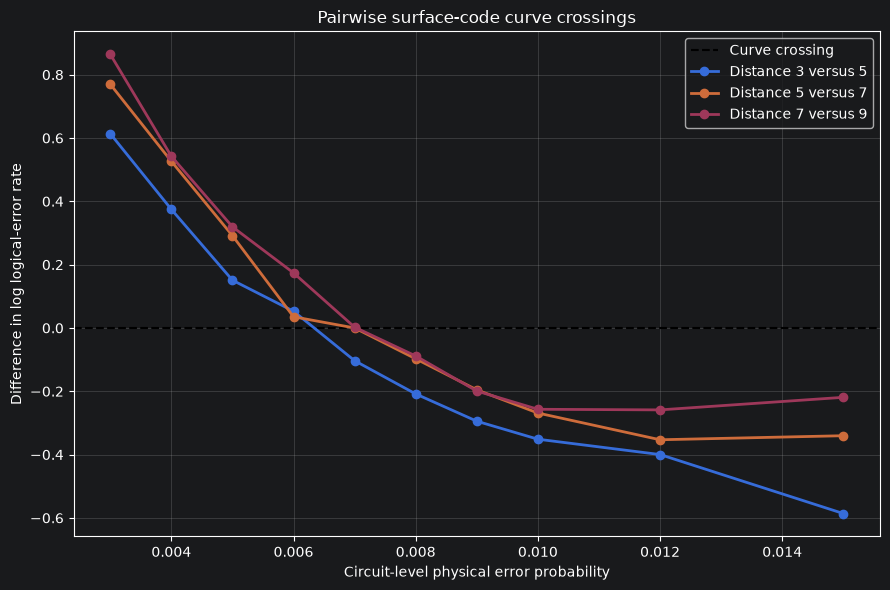

In [26]:
# Create new Matplotlib figure
figure, axis = plt.subplots(
    figsize=(9, 6)
)

# Draw a horizontal dashed reference line at y = 0.0
# Anywhere a curve crosses this line marks the exact error-correction threshold
axis.axhline(
    0.0,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Curve crossing",
)

# Loop through each pair of adjacent code distances and plot their log error differences
# against the tested hardware noise levels
for column_name, label in [
    (
        "d3_minus_d5",
        "Distance 3 versus 5",
    ),
    (
        "d5_minus_d7",
        "Distance 5 versus 7",
    ),
    (
        "d7_minus_d9",
        "Distance 7 versus 9",
    ),
]:
    axis.plot(
        # X-axis: Raw hardware noise levels
        crossing_analysis_df.index,
        # Y-axis: Log-difference between the two distances (above 0 = error suppression works)
        crossing_analysis_df[
            column_name
        ],
        marker="o",
        linewidth=2,
        label=label,
    )

# Label the X-axis, Y-axis, and overall chart title
axis.set_xlabel(
    "Circuit-level physical error probability"
)
axis.set_ylabel(
    "Difference in log logical-error rate"
)
axis.set_title(
    "Pairwise surface-code curve crossings"
)
# Add background grid and legend identifying each line
axis.grid(
    True,
    alpha=0.3,
)

axis.legend()

# Adjust padding so axis labels and titles do not get cut off
figure.tight_layout()

crossing_figure_path = (
    FIGURE_DIR
    / "surface_code_pairwise_crossings.png"
)

figure.savefig(
    crossing_figure_path,
    dpi=200,
    bbox_inches="tight",
)
# Render the final plot
plt.show()

# Preliminary Threshold Result

The logical-failure curves show a finite-distance crossing region around a circuit-level physical error probability of approximately **0.65% to 0.70%**.

* **Below the threshold (error suppression):** Increasing the rotated surface-code distance successfully reduced the logical decoding-failure probability. At a physical error probability of **0.3%**, increasing the distance from $d = 3$ to $d = 9$ lowered the measured logical failure rate from **$6.91 \times 10^{-3}$** to **$7.30 \times 10^{-4}$** — an improvement of roughly **9.5×**.
* **Above the threshold (error amplification):** Increasing the code distance worsened performance. At a physical error probability of **1.0%**, the $d = 9$ logical failure rate reached approximately **0.161**, compared with **0.067** for $d = 3$.

### Finite-Size Effects & Next Steps
The crossing point was not identical across all pairs of distances: the $d = 3$ curve intersected the larger-distance curves at a lower error probability than where the $d = 5, 7,$ and $9$ curves crossed one another. This drift is a classic signature of **finite-size effects**, meaning this initial sweep establishes a preliminary crossing region rather than a true asymptotic threshold.


To pinpoint the threshold more accurately, the next sweep will:
1. **Zoom in** on the **0.55% to 0.80%** physical error probability range with finer step sizes (`0.025%`).
2. **Shift to larger code distances** ($d \in \{5, 7, 9, 11\}$), dropping $d = 3$ to minimize small-system boundary artifacts.
3. **Apply uncertainty-aware finite-size scaling** using consistent statistical precision (`MAX_ERRORS = 2,000`).


In [27]:
# Define a tighter, higher-resolution range of hardware noise levels (0.55% to 0.80%, stepping by 0.025%)
# Running a finer sweep here gives a much more accurate zero-crossing estimate than a broad initial search
REFINED_PHYSICAL_ERROR_PROBABILITIES = [
    0.0055,
    0.00575,
    0.0060,
    0.00625,
    0.0065,
    0.00675,
    0.0070,
    0.00725,
    0.0075,
    0.00775,
    0.0080,
]

In [28]:
# Test larger code distances (5, 7, 9, and 11) for this high-precision sweep
# Threshold crossing much cleaner and more accurate as larger values reduces small-system finite-size effects
DISTANCES = [
    5,
    7,
    9,
    11,
]

# Increase runs for more accuracy
MAX_SHOTS = 2_000_000
MAX_ERRORS = 2_000

In [29]:
# CSV and Figure paths
RESULTS_CSV_PATH = (
    RESULTS_DIR
    / "surface_code_threshold_refined_sinter.csv"
)

SUMMARY_CSV_PATH = (
    RESULTS_DIR
    / "surface_code_threshold_refined_summary.csv"
)

FIGURE_PATH = (
    FIGURE_DIR
    / "surface_code_threshold_refined.png"
)